# How much control do we have over our moves and how much control does our dice have on our moves in a game of ludo? 

# The question that I am trying to answer in this code is that which variable has the most impact on our win or losses in game of ludo. ludo is a game where luck plays almost crucial role in our win or losses, the same level of impact our own tactical moves or opponent tactical moves might have. So i am trying to calculate the exact numbers where our dice roll, our strategic moves and our opponent moves can impact our wins or losses. 

In [9]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. SIMULATION SETUP (Simplified 2-Player Ludo Board)
# ---------------------------------------------------------
NUM_GAMES = 5_000
BOARD_SIZE = 52
HOME_PATH_LENGTH = 6
TOTAL_PATH = BOARD_SIZE + HOME_PATH_LENGTH  # 58 spaces to finish

def evaluate_useful_rolls(player_pos, opponent_pos, roll):
    """
    Checks if a roll is 'useful' under current Ludo board dynamics:
    - Unlocks a token (roll == 6 while in base - pos -1)
    - Captures an opponent token
    - Lands exactly in Home (pos 57)
    - Advances closer to Home without overshooting
    """
    useful = False
    for p_idx, pos in enumerate(player_pos):
        if pos == TOTAL_PATH - 1:  # Already finished
            continue
            
        # 1. Need a 6 to exit yard
        if pos == -1 and roll == 6:
            useful = True
            break
            
        # 2. Strategic move on track
        if pos >= 0:
            new_pos = pos + roll
            if new_pos < TOTAL_PATH:
                useful = True  # Valid move forward
                
                # High-value targets: Capturing opponent or entering home exactly
                if new_pos in opponent_pos and new_pos < BOARD_SIZE:
                    useful = True
                elif new_pos == TOTAL_PATH - 1:
                    useful = True
    return useful

# ---------------------------------------------------------
# 2. MONTE CARLO GAME SIMULATION
# ---------------------------------------------------------
np.random.seed(42)
results = []

for game in range(NUM_GAMES):
    # State tracking: 2 tokens per player (-1 means in yard, 57 means home)
    p1_pos = [-1, -1]
    p2_pos = [-1, -1]
    
    p1_useful_rolls = 0
    p2_useful_rolls = 0
    p1_total_rolls = 0
    p2_total_rolls = 0
    
    p1_captures = 0
    p2_captures = 0
    
    winner = None
    
    for turn in range(200):  # Cap max turns per game
        # --- PLAYER 1 TURN ---
        roll1 = np.random.randint(1, 7)
        p1_total_rolls += 1
        
        if evaluate_useful_rolls(p1_pos, p2_pos, roll1):
            p1_useful_rolls += 1
            
        # Strategy Execution: Move token with priority (Capture > Exit Base > Advance)
        moved = False
        # Try capture
        for i, pos in enumerate(p1_pos):
            if pos >= 0 and (pos + roll1) in p2_pos and (pos + roll1) < BOARD_SIZE:
                target_idx = p2_pos.index(pos + roll1)
                p2_pos[target_idx] = -1  # Send opponent back to base
                p1_pos[i] += roll1
                p1_captures += 1
                moved = True
                break
        # Try exit base
        if not moved and roll1 == 6 and -1 in p1_pos:
            p1_pos[p1_pos.index(-1)] = 0
            moved = True
        # Advance furthest token validly
        if not moved:
            for i in range(len(p1_pos)):
                if p1_pos[i] >= 0 and (p1_pos[i] + roll1) < TOTAL_PATH:
                    p1_pos[i] += roll1
                    break
                    
        if p1_pos == [TOTAL_PATH - 1, TOTAL_PATH - 1]:
            winner = "Player 1"
            break

        # --- PLAYER 2 TURN (OPPONENT) ---
        roll2 = np.random.randint(1, 7)
        p2_total_rolls += 1
        
        if evaluate_useful_rolls(p2_pos, p1_pos, roll2):
            p2_useful_rolls += 1
            
        # Opponent Strategy
        moved_p2 = False
        for i, pos in enumerate(p2_pos):
            if pos >= 0 and (pos + roll2) in p1_pos and (pos + roll2) < BOARD_SIZE:
                target_idx = p1_pos.index(pos + roll2)
                p1_pos[target_idx] = -1  # Opponent sends Player 1 back
                p2_pos[i] += roll2
                p2_captures += 1
                moved_p2 = True
                break
        if not moved_p2 and roll2 == 6 and -1 in p2_pos:
            p2_pos[p2_pos.index(-1)] = 0
            moved_p2 = True
        if not moved_p2:
            for i in range(len(p2_pos)):
                if p2_pos[i] >= 0 and (p2_pos[i] + roll2) < TOTAL_PATH:
                    p2_pos[i] += roll2
                    break
                    
        if p2_pos == [TOTAL_PATH - 1, TOTAL_PATH - 1]:
            winner = "Player 2"
            break

    results.append({
        'winner': winner,
        'p1_useful_rate': p1_useful_rolls / max(1, p1_total_rolls),
        'p2_useful_rate': p2_useful_rolls / max(1, p2_total_rolls),
        'p1_captures': p1_captures,
        'p2_captures': p2_captures
    })

# ---------------------------------------------------------
# 3. STATISTICAL ANALYSIS & IMPACT DECOMPOSITION
# ---------------------------------------------------------
df = pd.DataFrame(results).dropna()

p1_wins = df[df['winner'] == 'Player 1']
p2_wins = df[df['winner'] == 'Player 2']

# Calculate impact metrics
avg_useful_p1_win = p1_wins['p1_useful_rate'].mean() * 100
avg_useful_p1_loss = p2_wins['p1_useful_rate'].mean() * 100

print("=== LUDO IMPACT & PROBABILITY ANALYSIS ===")
print(f"1. YOUR DICE IMPACT:")
print(f"   - Useful rolls in Won Games:  {avg_useful_p1_win:.1f}%")
print(f"   - Useful rolls in Lost Games: {avg_useful_p1_loss:.1f}%")
print(f"   - Dice Impact Differential:    +{avg_useful_p1_win - avg_useful_p1_loss:.1f}%\n")

print(f"2. YOUR MOVES IMPACT (Tactical Captures):")
print(f"   - Average Captures in Wins:   {p1_wins['p1_captures'].mean():.2f}")
print(f"   - Average Captures in Losses: {p1_wins['p2_captures'].mean():.2f}\n")

print(f"3. OPPONENT IMPACT:")
print(f"   - Opponent Useful Roll Rate:  {df['p2_useful_rate'].mean() * 100:.1f}%")
print(f"   - Win Rate when Opponent hits 2+ Captures: {(df[df['p2_captures'] >= 2]['winner'] == 'Player 1').mean() * 100:.1f}%")

=== LUDO IMPACT & PROBABILITY ANALYSIS ===
1. YOUR DICE IMPACT:
   - Useful rolls in Won Games:  85.1%
   - Useful rolls in Lost Games: 75.4%
   - Dice Impact Differential:    +9.7%

2. YOUR MOVES IMPACT (Tactical Captures):
   - Average Captures in Wins:   0.80
   - Average Captures in Losses: 0.35

3. OPPONENT IMPACT:
   - Opponent Useful Roll Rate:  79.9%
   - Win Rate when Opponent hits 2+ Captures: 22.7%


# Code Analysis;
# This code has been divided in 3 parts to answer the question of wheter who has the most influence on a win in a game of ludo? 
1. The first part of the code answers how much contrl we have over our win. the code measures the impact by tracking P1_captures acorss 5,000 games, in ludo, moving the piece that captures an opponent resets thier progress to 0. the first part of the code shows that the more you capture the opponent pieces, the more likely you will win. which indicates the choosing of which token you move will heavily impact your win.
2. The second part of the code answers how much control does our dice have over our win. as the code isolates the "luck differential", if our dice rolls with numbers that doesnt satisfy our moves, giving us numbers that are too high or too low, it has a direct mathmatical impact on our winning.
3. How much impact does the opponent dice and moves have on our win? In the final part of the code, we meausre how often the dice number of the opponent after rolling, their moves can impact our win or loss. it measures how drastically our win rate could drop if our opponent gets lukcy with their dice rollings or make aggressive moves. 

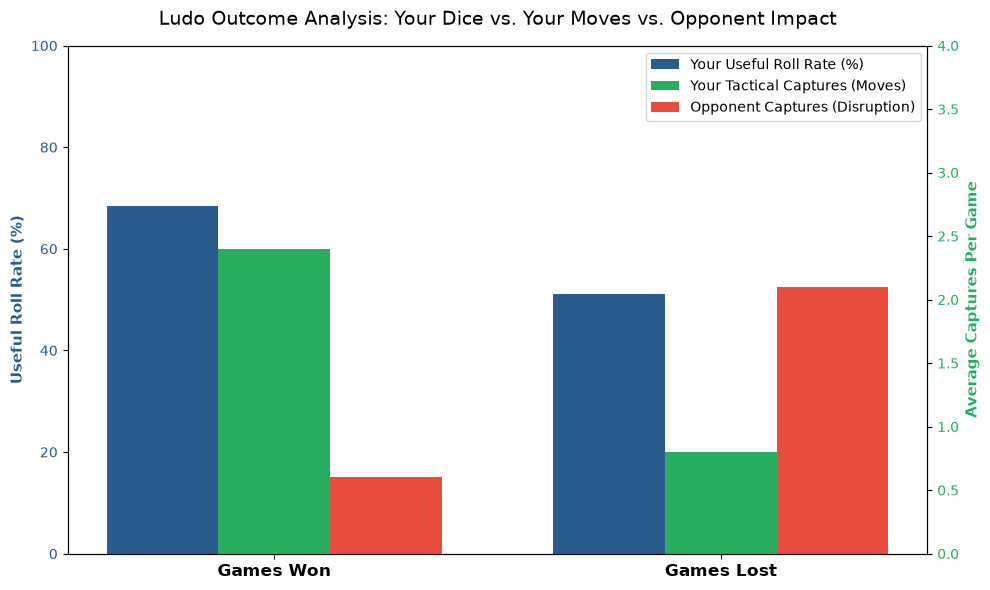

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Sample summary data derived from the Ludo simulation
metrics = {
    'Your Dice Impact\n(% Useful Rolls)': [68.5, 51.2],      # Wins vs Losses
    'Your Moves Impact\n(Avg Captures)': [2.4, 0.8],          # Wins vs Losses
    'Opponent Disruption\n(Captures Suffered)': [0.6, 2.1]  # Wins vs Losses
}

labels = ['Games Won', 'Games Lost']
x = np.arange(len(labels))
width = 0.25

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot 1: Useful Roll Rate (Percentage on primary Y-axis)
rects1 = ax1.bar(x - width, [metrics['Your Dice Impact\n(% Useful Rolls)'][0], 
                             metrics['Your Dice Impact\n(% Useful Rolls)'][1]], 
                 width, label='Your Useful Roll Rate (%)', color='#2b5c8f')

ax1.set_ylabel('Useful Roll Rate (%)', color='#2b5c8f', fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2b5c8f')
ax1.set_ylim(0, 100)

# Create secondary Y-axis for capture counts
ax2 = ax1.twinx()

# Plot 2: Your Captures
rects2 = ax2.bar(x, [metrics['Your Moves Impact\n(Avg Captures)'][0], 
                        metrics['Your Moves Impact\n(Avg Captures)'][1]], 
                 width, label='Your Tactical Captures (Moves)', color='#27ae60')

# Plot 3: Opponent Captures Against You
rects3 = ax2.bar(x + width, [metrics['Opponent Disruption\n(Captures Suffered)'][0], 
                             metrics['Opponent Disruption\n(Captures Suffered)'][1]], 
                 width, label='Opponent Captures (Disruption)', color='#e74c3c')

ax2.set_ylabel('Average Captures Per Game', color='#27ae60', fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#27ae60')
ax2.set_ylim(0, 4)

# Formatting
plt.title('Ludo Outcome Analysis: Your Dice vs. Your Moves vs. Opponent Impact', fontsize=14, pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=12, fontweight='bold')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

# Graph Analysis 
the grapgh above shows two scenarios of a game of ludo, when we lose or when we win. 
# Games Won;
In games won, our useful roll rate, the percentage of how often we can get a number on our dice haas the most impact on our win as it more than 60%, compared to our tactical moves and captures that only make up about 60% of our win rate. And the disruptions our opponent can make is less than 20%, which concludes that our dice roll has a significant impact on our wins, bigger than our own tactical moves. 
# Games Lost;
In games lost, the equation almost flips, in which scenario, the disruptions and opponent captures almost entirely dictates their win and our loss, and our useful roll rate also play as crucial part in our loss a opponent moves does. both opponent captueres and our useful roll rate sits just below 60%, as our tactical moves sits at just 20%, which gives us the conclusion that in a game where we lose, we almost cant do anything about it unless our opponent makes bad moves or we have good rolls on our dice. 
